In [8]:
import pandas as pd, yfinance as yf, datetime as dt, requests, io

retrieval_date = dt.date.today()
print("Retrieved:", retrieval_date)

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text
sp500 = pd.read_html(io.StringIO(html))[0]
sp500["Symbol"] = sp500["Symbol"].str.replace(".", "-", regex=False)  # BRK.B -> BRK-B for Yahoo
sp500.to_csv("sp500_tickers.csv", index=False)
print(len(sp500), "tickers")

Retrieved: 2026-11-21
503 tickers


In [9]:
tickers = sp500["Symbol"].tolist() + ["^GSPC"]
raw = yf.download(tickers, start="2021-01-01", end="2025-01-01",
                  auto_adjust=False, actions=True, group_by="ticker", threads=True)
raw.to_pickle("raw_prices.pkl")   # your preserved snapshot

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'VYLR', 'HONA', 'FDXF', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


In [10]:
import numpy as np

raw = pd.read_pickle("raw_prices.pkl")
adj   = raw.xs("Adj Close", axis=1, level=1)
close = raw.xs("Close",     axis=1, level=1)
vol   = raw.xs("Volume",    axis=1, level=1)

#  1.2 validation checks
print("Duplicate dates:", raw.index.duplicated().sum())
log = []
for t in adj.columns:
    if t == "^GSPC": continue
    a, c, v = adj[t], close[t], vol[t]
    if a.isna().all():
        log.append((t, "no data in period"))
    elif a.isna().any() or c.isna().any() or v.isna().any():
        log.append((t, f"missing values ({int(a.isna().sum())} days) - unequal history"))
    elif (a <= 0).any() or (c <= 0).any():
        log.append((t, "non-positive price"))
    elif (v < 0).any():
        log.append((t, "negative volume"))
    elif (v == 0).sum() > 5:
        log.append((t, "many zero-volume days"))
excl = pd.DataFrame(log, columns=["ticker", "reason"])
excl.to_csv("exclusion_log.csv", index=False)
print(excl["reason"].str.split(" \(").str[0].value_counts())

valid = [t for t in adj.columns if t != "^GSPC" and t not in set(excl.ticker)]
print("Valid shares:", len(valid))

# corporate actions check
actions = raw.xs("Stock Splits", axis=1, level=1)[valid]
print("Shares with a split in period:", int((actions > 0).any().sum()))
print("Shares where Adj Close differs from Close:", int((~np.isclose(adj[valid], close[valid])).any().sum()))

# --- 1.3 weekly returns (Friday-ending, last trading price in week) ---
wk = adj[valid + ["^GSPC"]].resample("W-FRI").last()
wk = wk.loc[:"2024-12-27"]                      # drop incomplete final week
ret = wk.pct_change().iloc[1:]                  # first row has no prior week
print("First/last week labels:", ret.index[0].date(), ret.index[-1].date(), "| n weeks:", len(ret))
assert ret.notna().all().all()                  # nothing silently filled

mean_ret = ret[valid].mean()
beta = ret[valid].apply(lambda s: s.cov(ret["^GSPC"]) / ret["^GSPC"].var())

features = pd.DataFrame({"mean_weekly_return": mean_ret, "beta": beta})
features["n_weeks"] = len(ret)
features.to_csv("features_return_beta.csv")
print(features.describe())

<>:26: SyntaxWarning: invalid escape sequence '\('
<>:26: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_11004/3514084596.py:26: SyntaxWarning: invalid escape sequence '\('
  print(excl["reason"].str.split(" \(").str[0].value_counts())


Duplicate dates: 0
reason
missing values           10
no data in period         5
many zero-volume days     2
Name: count, dtype: int64
Valid shares: 486
Shares with a split in period: 53
Shares where Adj Close differs from Close: 1
First/last week labels: 2021-01-15 2024-12-27 | n weeks: 207
       mean_weekly_return        beta  n_weeks
count          486.000000  486.000000    486.0
mean             0.002857    0.973695    207.0
std              0.002652    0.407339      0.0
min             -0.004468    0.055452    207.0
25%              0.001182    0.666599    207.0
50%              0.002619    0.950610    207.0
75%              0.004207    1.179538    207.0
max              0.017772    3.778560    207.0


In [11]:
# corrected corporate-action check
diff = ((adj[valid] - close[valid]).abs() > 1e-6 * close[valid]).any()
print("Shares where Adj Close != Close:", int(diff.sum()), "of", len(valid))
print(excl[excl.reason.str.contains("zero-volume")])

# --- 1.4 RFM ---
obs_date = adj[valid + ["^GSPC"]].dropna().index[-1]       # final common completed trading date
print("Observation date:", obs_date.date())

vol_v   = vol.loc[:obs_date, valid]
close_v = close.loc[:obs_date, valid]

base = vol_v.rolling(20).mean().shift(1)     # preceding 20 sessions, current day excluded
flag = vol_v > 2 * base                      # first 20 days have NaN baseline -> False

last_event = flag.apply(lambda s: s[s].index.max())          # NaT if no event
recency   = (obs_date - last_event).dt.days                  # NaN if no event (no zero substitution)
frequency = flag.iloc[-60:].sum()
monetary  = (close_v * vol_v).iloc[-60:].sum()

rfm = pd.DataFrame({"R": recency, "F": frequency, "M": monetary})
print("No-event shares:", int(rfm.R.isna().sum()))
print("Window:", close_v.index[-60].date(), "to", close_v.index[-1].date())
print(rfm.describe())

# worked example
t = "AAPL"
print(f"\n{t}: last event {last_event[t].date()}, R={rfm.R[t]}, F={rfm.F[t]}, M=${rfm.M[t]:,.0f}")
chk = pd.DataFrame({"vol": vol_v[t], "base20": base[t], "thresh": 2*base[t], "flag": flag[t]}).iloc[-60:]
print(chk[chk.flag])

feats = features.join(rfm)
feats.to_csv("features_all.csv")

Shares where Adj Close != Close: 398 of 486
  ticker                 reason
6     SW  many zero-volume days
7   FERG  many zero-volume days
Observation date: 2024-12-31
No-event shares: 0
Window: 2024-10-07 to 2024-12-31
                R           F             M
count  486.000000  486.000000  4.860000e+02
mean    20.407407    2.989712  3.940419e+10
std     21.342438    1.330800  1.291388e+11
min      4.000000    0.000000  1.297483e+09
25%     11.000000    2.000000  1.019517e+10
50%     11.000000    3.000000  1.668382e+10
75%     14.750000    4.000000  3.227689e+10
max    222.000000    8.000000  1.847697e+12

AAPL: last event 2024-12-20, R=11, F=2, M=$623,303,377,707
                  vol      base20      thresh  flag
Date                                               
2024-11-25   90152800  43820740.0  87641480.0  True
2024-12-20  147495300  45004605.0  90009210.0  True


486 shares in common set
mean_weekly_return     0.87
beta                   1.10
R                      3.65
F                      0.42
M                     11.68
logM                   1.08
dtype: float64
         matrix  k  ward_sil                         ward_sizes  km_sil  km_inertia                           km_sizes
0   risk_return  2     0.339                          [394, 92]   0.387     621.634                         [343, 143]
1   risk_return  3     0.274                     [230, 164, 92]   0.329     461.179                    [202, 165, 119]
2   risk_return  4     0.282                 [182, 164, 92, 48]   0.326     371.559                [159, 154, 132, 41]
3   risk_return  5     0.304              [182, 98, 92, 66, 48]   0.340     309.637            [169, 131, 109, 50, 27]
4   risk_return  6     0.320           [182, 98, 87, 66, 48, 5]   0.335     265.591         [150, 125, 109, 56, 41, 5]
5   risk_return  7     0.324       [160, 98, 87, 66, 48, 22, 5]   0.329     22

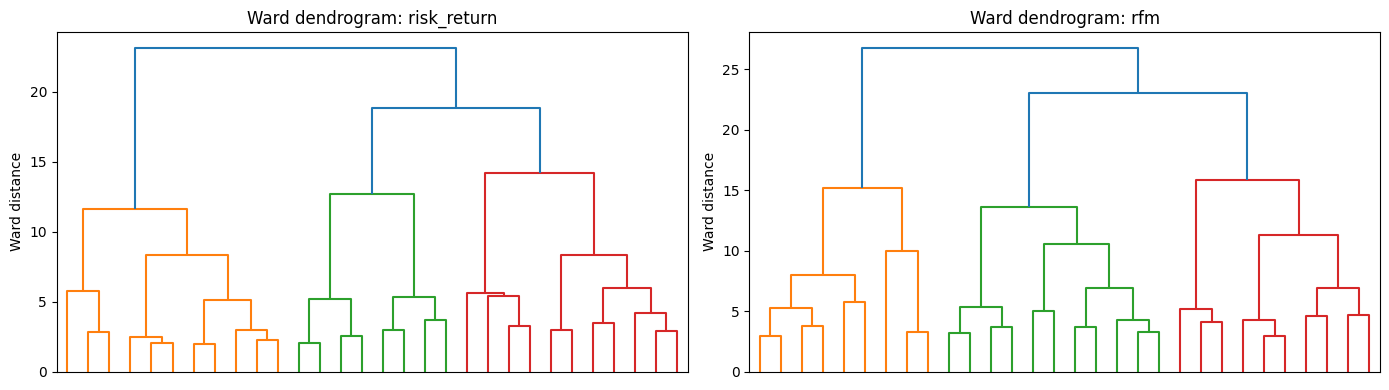

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

SEED = 42
df = feats.dropna().copy()                 # common share set (n = 486)
df["logM"] = np.log1p(df["M"])
print(len(df), "shares in common set")
print(df[["mean_weekly_return","beta","R","F","M","logM"]].skew().round(2))

X_rr  = StandardScaler().fit_transform(df[["mean_weekly_return","beta"]])
X_rfm = StandardScaler().fit_transform(df[["R","F","logM"]])
mats = {"risk_return": X_rr, "rfm": X_rfm}

# diagnostics for k = 2..8
rows = []
for name, X in mats.items():
    for k in range(2, 9):
        ag = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit(X)
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
        rows.append(dict(matrix=name, k=k,
            ward_sil=silhouette_score(X, ag.labels_),
            ward_sizes=sorted(np.bincount(ag.labels_), reverse=True),
            km_sil=silhouette_score(X, km.labels_),
            km_inertia=km.inertia_,
            km_sizes=sorted(np.bincount(km.labels_), reverse=True)))
diag = pd.DataFrame(rows)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
print(diag.round(3))
diag.to_csv("cluster_diagnostics.csv", index=False)

# dendrograms (one per matrix)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, X) in zip(axes, mats.items()):
    dendrogram(linkage(X, "ward"), truncate_mode="lastp", p=30, ax=ax, no_labels=True)
    ax.set_title(f"Ward dendrogram: {name}"); ax.set_ylabel("Ward distance")
plt.tight_layout(); plt.savefig("dendrograms.png", dpi=200); plt.show()


rr_ward
          mean_weekly_return    beta     R    F             M    n
rr_ward                                                          
0                    0.0055  1.2177  11.0  3.0  2.418413e+10   92
1                    0.0025  1.5139  11.0  3.0  2.869761e+10   48
2                    0.0017  0.9644  11.0  3.0  1.298483e+10  182
3                    0.0039  0.6663  11.0  3.0  1.764940e+10   98
4                    0.0011  0.4485  11.0  3.0  1.770109e+10   66

rr_km
        mean_weekly_return    beta     R    F             M    n
rr_km                                                          
0                  0.0019  0.5342  11.0  3.0  1.504389e+10  131
1                  0.0027  1.5430  11.0  3.0  3.214817e+10   50
2                  0.0042  0.9870  11.0  3.0  1.793137e+10  169
3                  0.0083  1.4497  11.0  3.0  2.821064e+10   27
4                  0.0008  1.0358  11.0  3.0  1.332965e+10  109

rfm_ward
           mean_weekly_return    beta      R    F             

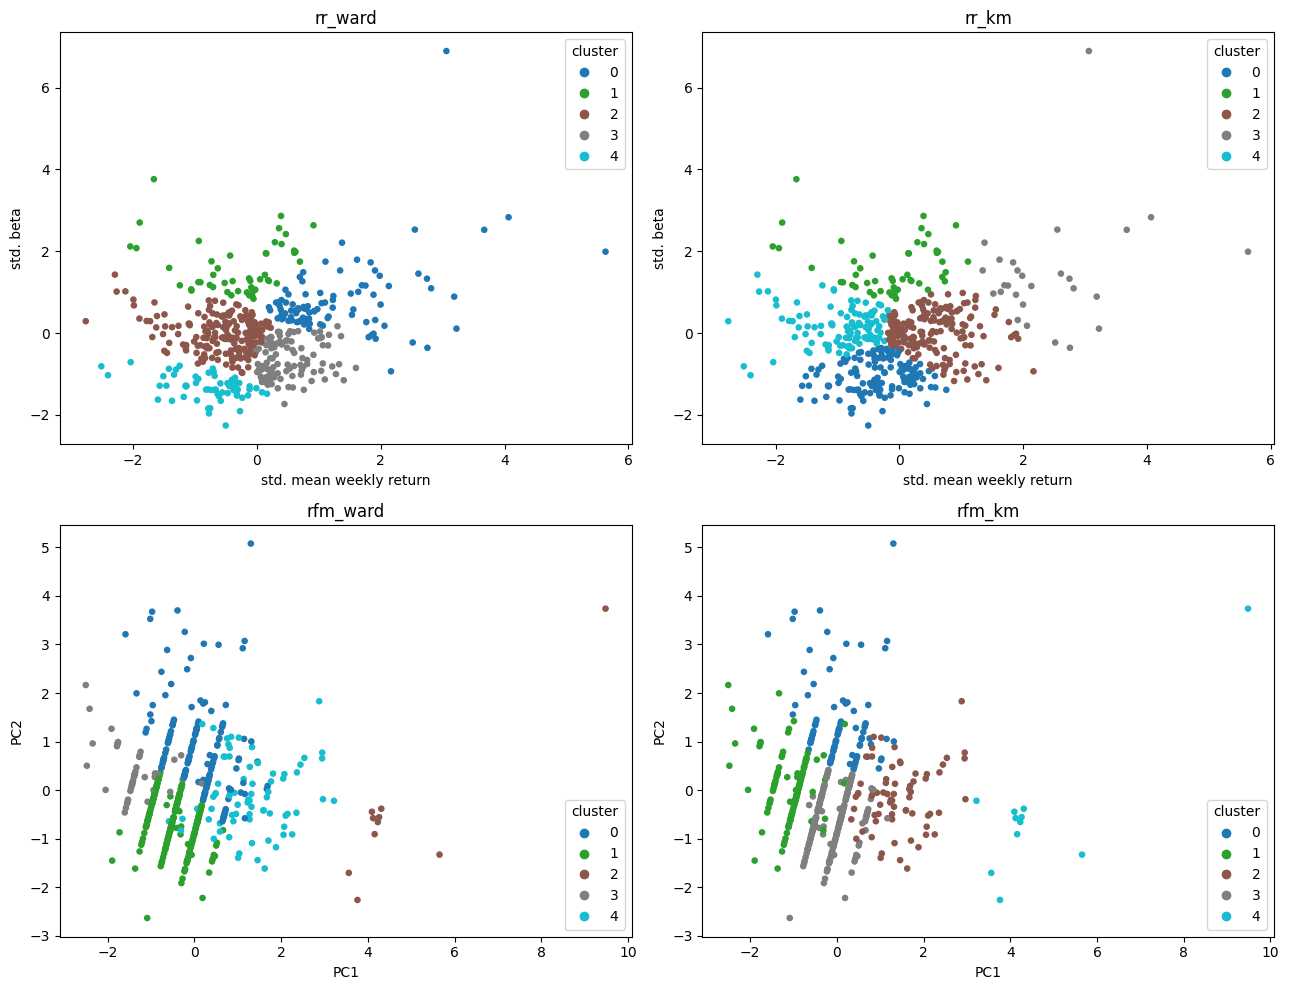

          R      F   logM
R     1.000 -0.346  0.152
F    -0.346  1.000  0.013
logM  0.152  0.013  1.000
ARI full RFM Ward vs R,F-only Ward: 0.335
rf_ward     0   1   2   3   4
rfm_ward                     
0          69   9  59   0  17
1         139   0  66   0   2
2           0   0   0  10   0
3           1   1   0   0  41
4           2  69   0   0   1
rf_ward
0    1.471409e+10
1    2.013167e+10
2    1.769899e+10
3    2.378595e+10
4    1.689492e+10
Name: M, dtype: float64


In [13]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score as ARI

K = 5
df["sector"] = sp500.set_index("Symbol")["GICS Sector"].reindex(df.index)

def fit(X, k):
    return (AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X),
            KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(X))
df["rr_ward"],  df["rr_km"]  = fit(X_rr,  K)
df["rfm_ward"], df["rfm_km"] = fit(X_rfm, K)

# profiles in original units (medians because of skew)
cols = ["mean_weekly_return","beta","R","F","M"]
for c in ["rr_ward","rr_km","rfm_ward","rfm_km"]:
    prof = df.groupby(c)[cols].median(); prof["n"] = df[c].value_counts().sort_index()
    print(f"\n{c}\n", prof.round(4))

# algorithm comparison (ARI ignores arbitrary label numbers)
print("\nARI Ward vs KMeans | risk-return:", round(ARI(df.rr_ward, df.rr_km), 3),
      "| RFM:", round(ARI(df.rfm_ward, df.rfm_km), 3))
print("ARI risk-return Ward vs RFM Ward:", round(ARI(df.rr_ward, df.rfm_ward), 3))

# sector composition (3.2.1)
print(pd.crosstab(df.sector, df.rfm_ward, normalize="columns").round(2))
print(pd.crosstab(df.sector, df.rr_ward, normalize="columns").round(2))

# labelled 2D visuals; PCA only needed for RFM (3 features -> 2)
pca = PCA(2, random_state=SEED).fit(X_rfm); P = pca.transform(X_rfm)
print("PCA explained variance:", pca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for a, (lab, X2, xl, yl) in zip(ax.ravel(), [
    ("rr_ward",  X_rr, "std. mean weekly return", "std. beta"),
    ("rr_km",    X_rr, "std. mean weekly return", "std. beta"),
    ("rfm_ward", P, "PC1", "PC2"), ("rfm_km", P, "PC1", "PC2")]):
    sc = a.scatter(X2[:,0], X2[:,1], c=df[lab], cmap="tab10", s=14)
    a.set_title(lab); a.set_xlabel(xl); a.set_ylabel(yl); a.legend(*sc.legend_elements(), title="cluster")
plt.tight_layout(); plt.savefig("cluster_plots.png", dpi=200); plt.show()

# 2.5.1 correlations
df["logR"] = np.log1p(df.R)
print(df[["R","F","logM"]].corr().round(3))

# 2.5.2 remove Monetary: R,F only, rescaled afresh, same shares, same K
lab_rf = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(
            StandardScaler().fit_transform(df[["R","F"]]))
df["rf_ward"] = lab_rf
print("ARI full RFM Ward vs R,F-only Ward:", round(ARI(df.rfm_ward, df.rf_ward), 3))
print(pd.crosstab(df.rfm_ward, df.rf_ward))
print(df.groupby("rf_ward")["M"].median().round(0))

df.to_csv("cluster_assignments.csv")

In [14]:
import sys, sklearn, scipy, matplotlib
print(sys.version.split()[0], pd.__version__, np.__version__, sklearn.__version__,
      scipy.__version__, matplotlib.__version__, yf.__version__)

3.13.18 2.2.3 2.4.6 1.6.1 1.16.3 3.10.0 0.2.66


In [15]:
import glob, zipfile
from google.colab import files

names = glob.glob("*.csv") + glob.glob("*.png") + glob.glob("*.pkl")
with zipfile.ZipFile("project_files.zip", "w") as z:
    for n in names: z.write(n)
print(names)
files.download("project_files.zip")

['exclusion_log.csv', 'cluster_assignments.csv', 'cluster_diagnostics.csv', 'features_all.csv', 'sp500_tickers.csv', 'features_return_beta.csv', 'dendrograms.png', 'cluster_plots.png', 'raw_prices.pkl']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>